# 🏭 DL & GenAI Project (T3-2026) — Milestone 3 notebook
Roll no. `23f3001567` · W&B project `23f3001567-t32026` · *Transfer learning & stronger segmentation models*

**How to use:** Kaggle → add the competition data → **GPU T4 + Internet ON** (needed for `segmentation_models_pytorch` and the ImageNet weights) + secret `WANDB_API_KEY` → *Run All* (≈ 40–50 min; most of it is the three 5-epoch trainings of Q8/Q9).
The last cell prints an **ANSWER SHEET**: one line per question in the exact "Answer format" of the Google Form.

| Question | Topic | How it is answered |
|---|---|---|
| Q1 | feature-map geometry, odd-width mismatch | arithmetic + simulation |
| Q2 | SMP U-Net parameter audit (ResNet-34 vs EfficientNet-B0), frozen encoder | **counted with `segmentation_models_pytorch`** |
| Q3 | grayscale adaptation (sum vs mean) | numerical proof |
| Q4 | atrous convolution footprint | formula + short text |
| Q5 | Soft Dice numbers | formula |
| Q6 | softmax vs sigmoid heads | short text |
| Q7 | compound loss on clean images | numerical gradient check + short text |
| Q8 | scratch vs pretrained ResNet-34 (5 epochs) | **training** |
| Q9 | ResNet-34 vs EfficientNet-B0 | **training + parameter/VRAM measurement** |

**Assumptions (the form does not spell them out):** full training set with the 80/20 stratified split (seed 42) used in the main project; threshold 0.5, no minimum area for the official score; CompoundLoss = 0.5·BCE + 0.5·Soft-Dice (ε = 1, Dice computed per image-class pair); scratch model = the project's from-scratch U-Net; pretrained models = `smp.Unet(..., encoder_weights="imagenet", in_channels=1, classes=4)`; light flip augmentation for all models. Change `SUBSET_N` to train on fewer images.

In [42]:
# ===================== SETTINGS =====================
ROLL_NO       = "23f3001567"
WANDB_PROJECT = f"{ROLL_NO}-t32026"
INPUT_ROOT, OUT_DIR = "/kaggle/input", "/kaggle/working"
QUICK_TEST    = False       # True = tiny dry run (few images, 1 epoch) just to check that the code runs; answers are then meaningless
SUBSET_N      = None        # None = all training images; e.g. 3000 = faster, less accurate
SEED, BATCH, LR, WD, EPOCHS, THR = 42, 16, 3e-4, 1e-2, 5, 0.5

import os, json, math, random, copy, time, warnings, subprocess, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
H, W = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
os.makedirs(OUT_DIR, exist_ok=True)
ANS = {}          # formatted answers for the Google Form are collected here
print("settings ok")

settings ok


## Question 1 — feature-map geometry and downsampling arithmetic

In [43]:
def pool(n): return n // 2                                    # MaxPool2d(kernel 2, stride 2): floor division
def up(n):   return n * 2                                     # transposed conv / upsample x2
# (1) bottleneck of the native 128 x 800 strip
h, w = 128, 800; shapes = [(h, w)]
for _ in range(4): h, w = pool(h), pool(w); shapes.append((h, w))
print("native strip shapes:", shapes)
Hb, Wb = shapes[-1]
# (2) odd width 128 x 799, unpadded
h, w = 128, 799; enc = [(h, w)]
for _ in range(4): h, w = pool(h), pool(w); enc.append((h, w))
print("odd-width strip shapes:", enc)
mism = []
for lvl in range(4, 0, -1):                                   # decoder: upsample level `lvl`, then concatenate with the skip of level lvl-1
    up_w, skip_w = up(enc[lvl][1]), enc[lvl - 1][1]
    mism.append(skip_w - up_w); print(f"  decoder merge {lvl}->{lvl-1}: upsampled width {up_w} vs skip width {skip_w} -> mismatch {skip_w - up_w} px")
q1_mismatch = mism[0]                                         # the deepest (first) skip-connection concatenation: 98 vs 99
q1_factor = (128 * 800) / (Hb * Wb)
print(f"(1) bottleneck: ({Hb}, {Wb})\n(2) width mismatch at the skip-connection concatenation: {q1_mismatch} px\n(3) area downsampling factor: {q1_factor:.0f}x  (= {128 * 800} / {Hb * Wb})")
ANS["Q1"] = f"{Hb}, {Wb}; {q1_mismatch}; {q1_factor:.0f}"

native strip shapes: [(128, 800), (64, 400), (32, 200), (16, 100), (8, 50)]
odd-width strip shapes: [(128, 799), (64, 399), (32, 199), (16, 99), (8, 49)]
  decoder merge 4->3: upsampled width 98 vs skip width 99 -> mismatch 1 px
  decoder merge 3->2: upsampled width 198 vs skip width 199 -> mismatch 1 px
  decoder merge 2->1: upsampled width 398 vs skip width 399 -> mismatch 1 px
  decoder merge 1->0: upsampled width 798 vs skip width 799 -> mismatch 1 px
(1) bottleneck: (8, 50)
(2) width mismatch at the skip-connection concatenation: 1 px
(3) area downsampling factor: 256x  (= 102400 / 400)


## Question 2 — pretrained backbone architecture and parameter audit (SMP)
Installs/uses `segmentation_models_pytorch` (Internet must be ON). Models are built with `in_channels=1, classes=4`; no weights are needed just to **count** parameters.

In [44]:
try:
    import segmentation_models_pytorch as smp
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch", "efficientnet-pytorch", "pretrainedmodels", "timm"], check=False)
    import segmentation_models_pytorch as smp
import torch, torch.nn as nn, torch.nn.functional as F
print("segmentation_models_pytorch", smp.__version__, "| torch", torch.__version__)

def make_smp(encoder, weights=None):
    return smp.Unet(encoder_name=encoder, encoder_weights=weights, in_channels=1, classes=4)
def count(m, trainable_only=False): return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

EFF_NAME = None
for cand in ["efficientnet-b0", "timm-efficientnet-b0", "tu-efficientnet_b0"]:         # the form uses "efficientnet-b0"; fall back only if this SMP version dropped the name
    try: make_smp(cand); EFF_NAME = cand; break
    except Exception as e: print("encoder", cand, "not available:", repr(e)[:90])
print("EfficientNet encoder name used:", EFF_NAME)

m_res, m_eff = make_smp("resnet34"), make_smp(EFF_NAME)
p_res, p_eff = count(m_res), count(m_eff)
more_eff = "efficientnet-b0" if p_eff < p_res else "resnet34"
diff = abs(p_res - p_eff)
enc_res = sum(p.numel() for p in m_res.encoder.parameters())
for p in m_res.encoder.parameters(): p.requires_grad = False                           # frozen-encoder feature extractor
train_res = count(m_res, trainable_only=True); q2_pct = 100 * train_res / p_res
print(f"ResNet-34 U-Net      : {p_res:,} parameters (encoder {enc_res:,})\nEfficientNet-B0 U-Net: {p_eff:,} parameters\nmore parameter-efficient: {more_eff} | difference {diff:,}")
print(f"frozen encoder -> trainable {train_res:,} of {p_res:,} = {q2_pct:.4f} %   -> {q2_pct:.1f} %")
print("hand-check for ResNet-34 (in_channels=1, classes=4): 24,436,369 - 6,272 (conv1) + 435 (head) = 24,430,532 ->", "OK" if p_res == 24_430_532 else f"differs ({p_res:,}) - this SMP version has a different default; use the counted value")
del m_res, m_eff
ANS["Q2"] = f"{more_eff}, {diff}; {q2_pct:.1f}"

segmentation_models_pytorch 0.6.0 | torch 2.11.0+cu130
EfficientNet encoder name used: efficientnet-b0
ResNet-34 U-Net      : 24,430,532 parameters (encoder 21,278,400)
EfficientNet-B0 U-Net: 6,251,328 parameters
more parameter-efficient: efficientnet-b0 | difference 18,179,204
frozen encoder -> trainable 3,152,132 of 24,430,532 = 12.9024 %   -> 12.9 %
hand-check for ResNet-34 (in_channels=1, classes=4): 24,436,369 - 6,272 (conv1) + 435 (head) = 24,430,532 -> OK


## Question 3 — grayscale input adaptation (sum or mean?)

In [45]:
rng = np.random.RandomState(0)
Wrgb = rng.randn(64, 3, 7, 7)                      # pretrained conv1 weights (out, in=3, kH, kW)
patch = rng.rand(1, 7, 7)                          # a grayscale image patch I
rep = np.repeat(patch, 3, axis=0)                  # Strategy A: [I, I, I]
out_A    = np.einsum("ockl,ckl->o", Wrgb, rep)                         # conv1 on the duplicated image
out_sum  = np.einsum("ockl,ckl->o", Wrgb.sum(1, keepdims=True), patch)  # Strategy B with W_gray = sum over channels
out_mean = np.einsum("ockl,ckl->o", Wrgb.mean(1, keepdims=True), patch) # Strategy B with W_gray = mean over channels
print("sum  == Strategy A:", np.allclose(out_A, out_sum), "| mean == Strategy A:", np.allclose(out_A, out_mean), "(mean is 3x too small)")
bytes_A, bytes_B = 16 * 3 * 128 * 800 * 4, 16 * 1 * 128 * 800 * 4
q3_factor = bytes_A / bytes_B
print(f"batch of 16 float32: Strategy A {bytes_A / 1e6:.1f} MB vs Strategy B {bytes_B / 1e6:.1f} MB -> {q3_factor:.0f}x less transfer")
ANS["Q3"] = f"{'sum' if np.allclose(out_A, out_sum) else 'mean'}, {q3_factor:.0f}"

sum  == Strategy A: True | mean == Strategy A: False (mean is 3x too small)
batch of 16 float32: Strategy A 19.7 MB vs Strategy B 6.6 MB -> 3x less transfer


## Question 4 — atrous convolutions  `k' = k + (k-1)(r-1)`

In [46]:
def k_eff(k, r): return k + (k - 1) * (r - 1)
k6, k12 = k_eff(3, 6), k_eff(3, 12)
q4_text = ("ASPP runs parallel dilated convolutions with different rates, so small rates keep full-resolution detail for 1-3 px hairline cracks (defect_a) while large rates "
           "give wide context for big diffuse patches (defect_c) - a large receptive field and multi-scale context without pooling away resolution or adding parameters, unlike a pooling bottleneck.")
print(f"3x3 kernel: r=6 -> {k6}x{k6} | r=12 -> {k12}x{k12}\n{q4_text}")
ANS["Q4"] = f"{k6}, {k12}; {q4_text}"

3x3 kernel: r=6 -> 13x13 | r=12 -> 25x25
ASPP runs parallel dilated convolutions with different rates, so small rates keep full-resolution detail for 1-3 px hairline cracks (defect_a) while large rates give wide context for big diffuse patches (defect_c) - a large receptive field and multi-scale context without pooling away resolution or adding parameters, unlike a pooling bottleneck.


## Question 5 — differentiable Soft Dice loss

In [47]:
def soft_dice_loss(p, y, eps=1.0):
    return 1 - (2 * (p * y).sum() + eps) / (p.sum() + y.sum() + eps)
y = np.r_[np.ones(100), np.zeros(9900)]
p1 = np.full(10000, 0.01)                                      # lazy model
p2 = np.r_[np.full(100, 0.90), np.zeros(9900)]                 # accurate model
l1, l2 = soft_dice_loss(p1, y), soft_dice_loss(p2, y)
print(f"model 1: 1 - (2*1 + 1)/(100 + 100 + 1) = {l1:.6f} -> {l1:.4f}\nmodel 2: 1 - (2*90 + 1)/(90 + 100 + 1) = {l2:.6f} -> {l2:.4f}")
ANS["Q5"] = f"{l1:.4f}, {l2:.4f}"

model 1: 1 - (2*1 + 1)/(100 + 100 + 1) = 0.985075 -> 0.9851
model 2: 1 - (2*90 + 1)/(90 + 100 + 1) = 0.052356 -> 0.0524


## Question 6 — sigmoid (multi-label) vs softmax (multi-class) heads

In [48]:
q6_yes = "Yes"
q6_text = ("Softmax forces every pixel into exactly one class, so if annotations ever overlap the classes compete for the same pixel: one label is suppressed or the probabilities are split, "
           "causing missed or under-confident detections, whereas independent sigmoid channels can mark a pixel as several defects.")
print(q6_yes, "- defect_a on the left and defect_c on the right occupy different pixels, so each pixel simply takes its own class.\n" + q6_text)
ANS["Q6"] = f"{q6_yes}; {q6_text}"

Yes - defect_a on the left and defect_c on the right occupy different pixels, so each pixel simply takes its own class.
Softmax forces every pixel into exactly one class, so if annotations ever overlap the classes compete for the same pixel: one label is suppressed or the probabilities are split, causing missed or under-confident detections, whereas independent sigmoid channels can mark a pixel as several defects.


## Question 7 — compound loss on clean images (numerical check)

In [49]:
# clean image |Y| = 0 : Dice loss = 1 - 1/(S + 1) with S = sum(p).  dLoss/dp_i = 1/(S+1)^2 for every pixel
for S in [0.0, 1.0, 10.0, 50.0, 500.0]:
    print(f"sum p = {S:6.0f} | Dice loss = {1 - 1 / (S + 1):.4f} | gradient per pixel = {1 / (S + 1) ** 2:.6f}")
q7_a = ("On a clean image Dice loss is 0 for an empty prediction, but as soon as stray pixels appear it jumps to about 0.98 almost regardless of how few there are "
        "(a step-like penalty), while its gradient 1/(sum p + 1)^2 is tiny and identical for every pixel (about 4e-4 at 50 stray pixels), so it pushes all probabilities down only weakly and unstably.")
q7_b = ("BCE gives a stable, dense per-pixel gradient on every image (including clean ones) and keeps probabilities calibrated, while Dice alone is noisy/vanishing on empty masks; "
        "Dice in turn handles the class imbalance and optimises overlap, so the combination gets both stability and good segmentation.")
print("\n" + q7_a + "\n" + q7_b)
ANS["Q7"] = f"{q7_a}; {q7_b}"

sum p =      0 | Dice loss = 0.0000 | gradient per pixel = 1.000000
sum p =      1 | Dice loss = 0.5000 | gradient per pixel = 0.250000
sum p =     10 | Dice loss = 0.9091 | gradient per pixel = 0.008264
sum p =     50 | Dice loss = 0.9804 | gradient per pixel = 0.000384
sum p =    500 | Dice loss = 0.9980 | gradient per pixel = 0.000004

On a clean image Dice loss is 0 for an empty prediction, but as soon as stray pixels appear it jumps to about 0.98 almost regardless of how few there are (a step-like penalty), while its gradient 1/(sum p + 1)^2 is tiny and identical for every pixel (about 4e-4 at 50 stray pixels), so it pushes all probabilities down only weakly and unstably.
BCE gives a stable, dense per-pixel gradient on every image (including clean ones) and keeps probabilities calibrated, while Dice alone is noisy/vanishing on empty masks; Dice in turn handles the class imbalance and optimises overlap, so the combination gets both stability and good segmentation.


## Data for the training questions (Q8, Q9)
Same pipeline as the main project: official `train.csv`, RLE decoded column-major / 1-based, 80/20 split stratified on the defect pattern (seed 42).

In [50]:
from sklearn.model_selection import train_test_split
import cv2
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); USE_AMP = device.type == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if USE_AMP else "NO GPU -> switch on the T4 accelerator!")
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

try:
    from kaggle_secrets import UserSecretsClient
    import wandb
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY")); print("✅ W&B login OK, project:", WANDB_PROJECT)
except Exception as e:
    os.environ["WANDB_MODE"] = "disabled"; import wandb
    print("⚠️ W&B DISABLED (", repr(e)[:80], ") -> add the secret WANDB_API_KEY, otherwise the runs are NOT logged")

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
def find_file(root, names):
    for d, _, fs in os.walk(root):
        for n in names:
            if n in fs: return os.path.join(d, n)
TRAIN_CSV = find_file(INPUT_ROOT, ["train.csv", "train_1.csv"]); assert TRAIN_CSV, "train.csv not found - add the competition as Input"
train_dir = max(((d, sum(f.lower().endswith(IMG_EXT) for f in fs)) for d, _, fs in os.walk(INPUT_ROOT) if os.path.basename(d) == "train"), key=lambda t: t[1])[0]
PATHS = {os.path.splitext(f)[0]: os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.lower().endswith(IMG_EXT)}

def rle_to_mask(rle, shape=(H, W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        nums = np.array(rle.split(), dtype=np.int64)
        for s, l in zip(nums[0::2] - 1, nums[1::2]):
            a, b = max(int(s), 0), min(int(s + l), H * W)
            if b > a: flat[a:b] = 1
    return flat.reshape(shape, order="F")

train_df = pd.read_csv(TRAIN_CSV); train_df["image_id"] = train_df.image_id.astype(str)
rle_pivot = train_df.pivot(index="image_id", columns="defect_type", values="mask_rle")[CLASSES].fillna("")
if QUICK_TEST: SUBSET_N = 300
if SUBSET_N: rle_pivot = rle_pivot.sort_index().iloc[:SUBSET_N]
has = (rle_pivot != "").astype(int); rle_table = {i: list(r) for i, r in zip(rle_pivot.index, rle_pivot.values)}; all_ids = list(has.index)
pattern = has.astype(str).agg("".join, axis=1); pattern = pattern.where(pattern.map(pattern.value_counts()) >= 3, "rare")
train_ids, val_ids = train_test_split(all_ids, test_size=0.2, stratify=pattern.loc[all_ids], random_state=SEED)
def load_gray(p):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE); return im if im.shape == (H, W) else cv2.resize(im, (W, H), interpolation=cv2.INTER_AREA)
with ThreadPoolExecutor(8) as ex: images = dict(zip(all_ids, tqdm(ex.map(lambda i: load_gray(PATHS[i]), all_ids), total=len(all_ids), leave=False)))
sub = np.stack([images[i] for i in train_ids[:2000]]).astype(np.float32) / 255.0; PIX_MEAN, PIX_STD = float(sub.mean()), float(sub.std()); del sub
print(f"{len(all_ids)} images | train {len(train_ids)} | validation {len(val_ids)} | mean/std {PIX_MEAN:.3f}/{PIX_STD:.3f}")

class DS(Dataset):
    def __init__(self, ids, augment=False): self.ids, self.augment = list(ids), augment
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        iid = self.ids[k]; img = images[iid].astype(np.float32) / 255.0; m = np.stack([rle_to_mask(r) for r in rle_table[iid]])
        if self.augment:
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, :, ::-1]
            if random.random() < 0.5: img, m = img[::-1, :], m[:, ::-1, :]
        img = (img - PIX_MEAN) / PIX_STD
        return torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(m)).float()
WORKERS = 2 if USE_AMP else 0
val_loader = DataLoader(DS(val_ids), batch_size=32, shuffle=False, num_workers=WORKERS)

# ---- official metric (0.7 foreground Dice + 0.2 false-positive score + 0.1 empty accuracy) ----
def competition_score(inter, pa, ga):
    inter, pa, ga = [np.asarray(a, dtype=np.float64) for a in (inter, pa, ga)]
    pos = ga > 0; dice = 2 * inter / np.maximum(pa + ga, 1)
    fg = dice[pos].mean() if pos.any() else 0.0
    fps = 1 - (pa[~pos] / (H * W)).mean() if (~pos).any() else 1.0
    eacc = (pa[~pos] == 0).mean() if (~pos).any() else 1.0
    return dict(score=0.7 * fg + 0.2 * fps + 0.1 * eacc, fg_dice=fg, empty_acc=eacc)

# ---- CompoundLoss(alpha=0.5, beta=0.5, smooth=1.0) = 0.5 * BCE + 0.5 * Soft Dice (per image-class pair) ----
bce = nn.BCEWithLogitsLoss()
class CompoundLoss(nn.Module):
    def __init__(self, alpha=0.5, beta=0.5, smooth=1.0): super().__init__(); self.alpha, self.beta, self.smooth = alpha, beta, smooth
    def forward(self, logits, y):
        logits = logits.float(); p = torch.sigmoid(logits)
        inter, den = (p * y).sum((2, 3)), p.sum((2, 3)) + y.sum((2, 3))
        dice_loss = (1 - (2 * inter + self.smooth) / (den + self.smooth)).mean()
        return self.alpha * bce(logits, y) + self.beta * dice_loss
criterion = CompoundLoss(0.5, 0.5, 1.0)

@torch.no_grad()
def evaluate(model):
    model.eval(); I, P, G, losses = [], [], [], []
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP): logits = model(x)
        losses.append(criterion(logits, y).item() * len(x)); pred, g = torch.sigmoid(logits.float()) > THR, y.bool()
        I.append((pred & g).sum((2, 3)).cpu()); P.append(pred.sum((2, 3)).cpu()); G.append(g.sum((2, 3)).cpu())
    m = competition_score(*[torch.cat(a).numpy() for a in (I, P, G)]); m["val_loss"] = sum(losses) / len(val_loader.dataset); return m
print("data + loss + metric ready")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


device: cuda | Tesla T4
✅ W&B login OK, project: 23f3001567-t32026


  0%|          | 0/11393 [00:00<?, ?it/s]

11393 images | train 9114 | validation 2279 | mean/std 0.347/0.190
data + loss + metric ready


## Models for Q8 / Q9 and the training function

In [51]:
class ConvBlock(nn.Sequential):                                          # (3x3 conv -> BatchNorm -> ReLU) twice
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SimpleUNet(nn.Module):                                             # MODEL 1: U-Net from scratch
    def __init__(self, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]              # 32, 64, 128, 256, 512 channels
        self.enc = nn.ModuleList([ConvBlock(1, c[0]), ConvBlock(c[0], c[1]), ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])])
        self.bottom = ConvBlock(c[3], c[4])
        self.pool = nn.MaxPool2d(2)                                      # halves height and width
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])   # learnable up-sampling x2
        self.dec = nn.ModuleList([ConvBlock(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], NC, 1)
        nn.init.constant_(self.head.bias, -4.0)                          # start at "~2 % probability" (defects are rare) -> stable start
    def forward(self, x):
        skips = []
        for enc in self.enc:                                             # ENCODER: go down, remember every level
            x = enc(x); skips.append(x); x = self.pool(x)
        x = self.bottom(x)
        for i in (3, 2, 1, 0):                                           # DECODER: go up, add the remembered level (skip connection)
            x = self.dec[i](torch.cat([self.up[i](x), skips[i]], 1))
        return self.head(x)                                              # raw scores (logits) (B, 4, H, W)

def build(tag):
    if tag == "scratch":   return SimpleUNet()                                                     # from-scratch U-Net (random weights)
    if tag == "resnet34":  return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=1, classes=4)
    if tag == "effb0":     return smp.Unet(encoder_name=EFF_NAME, encoder_weights="imagenet", in_channels=1, classes=4)

RESULTS = {}
def train_model(tag, epochs=EPOCHS):
    seed_everything(SEED)
    model = build(tag).to(device); n_params = sum(p.numel() for p in model.parameters())
    loader = DataLoader(DS(train_ids, augment=True), batch_size=BATCH, shuffle=True, num_workers=WORKERS, drop_last=False, persistent_workers=WORKERS > 0)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    if USE_AMP: torch.cuda.reset_peak_memory_stats()
    wandb.init(project=WANDB_PROJECT, name=f"m3_{tag}", reinit=True, config=dict(milestone=3, model=tag, params=n_params, epochs=epochs, lr=LR, weight_decay=WD, batch=BATCH, loss="CompoundLoss(0.5,0.5,1.0)", threshold=THR))
    hist, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for x, y in tqdm(loader, desc=f"{tag} epoch {ep}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP): logits = model(x)
            loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(x)
        ev = evaluate(model); row = dict(epoch=ep, train_loss=run / len(loader.dataset), val_loss=ev["val_loss"], val_score=ev["score"], val_fg_dice=ev["fg_dice"], val_empty_acc=ev["empty_acc"])
        row["gap"] = row["val_loss"] - row["train_loss"]; hist.append(row); wandb.log(row)
        print(f"[{tag}] epoch {ep}/{epochs} | train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | gap {row['gap']:+.4f} | score {row['val_score']:.4f} | fg_dice {row['val_fg_dice']:.4f} | {(time.time() - t0) / 60:.1f} min")
    vram = torch.cuda.max_memory_allocated() / 2**20 if USE_AMP else float("nan")
    wandb.run.summary.update(dict(final_val_score=hist[-1]["val_score"], peak_vram_mb=vram, params=n_params)); wandb.finish()
    RESULTS[tag] = dict(hist=pd.DataFrame(hist), params=n_params, vram_mb=vram, minutes=(time.time() - t0) / 60)
    del model, opt, loader; torch.cuda.empty_cache()
print("training tools ready")

training tools ready


## Question 8 — scratch U-Net vs pretrained ResNet-34 U-Net (5 epochs each)

In [52]:
train_model("scratch")
train_model("resnet34")

scratch epoch 1:   0%|          | 0/570 [00:00<?, ?it/s]

[scratch] epoch 1/5 | train_loss 0.5028 | val_loss 0.4924 | gap -0.0104 | score 0.4822 | fg_dice 0.2881 | 3.1 min


scratch epoch 2:   0%|          | 0/570 [00:00<?, ?it/s]

[scratch] epoch 2/5 | train_loss 0.4465 | val_loss 0.3337 | gap -0.1127 | score 0.5389 | fg_dice 0.3721 | 6.2 min


scratch epoch 3:   0%|          | 0/570 [00:00<?, ?it/s]

[scratch] epoch 3/5 | train_loss 0.2285 | val_loss 0.1742 | gap -0.0543 | score 0.4686 | fg_dice 0.2620 | 9.3 min


... (15 outputs left out)

[resnet34] epoch 4/5 | train_loss 0.1331 | val_loss 0.1452 | gap +0.0121 | score 0.3472 | fg_dice 0.0766 | 9.4 min


resnet34 epoch 5:   0%|          | 0/570 [00:00<?, ?it/s]

[resnet34] epoch 5/5 | train_loss 0.1335 | val_loss 0.1449 | gap +0.0114 | score 0.3082 | fg_dice 0.0122 | 11.7 min


epoch,▁▃▅▆█
gap,▄▇▁██
train_loss,█▇▃▁▁
val_empty_acc,▄▁█▇█
val_fg_dice,▇█▁▂▁
val_loss,██▁▁▁
val_score,▇█▁▂▁
epoch,5
final_val_score,0.30824
gap,0.01137
params,24430532


In [53]:
s, r = RESULTS["scratch"]["hist"].set_index("epoch"), RESULTS["resnet34"]["hist"].set_index("epoch")
display(pd.concat({"scratch": s.round(4), "resnet34": r.round(4)}, axis=1))
E = EPOCHS
lower_loss  = "pretrained" if r.val_loss[E] < s.val_loss[E] else "scratch"
higher_score = "pretrained" if r.val_score[E] > s.val_score[E] else "scratch"
winning = lower_loss if lower_loss == higher_score else f"{higher_score} (higher score; {lower_loss} has the lower val loss)"
faster1 = "pretrained" if r.val_fg_dice[1] > s.val_fg_dice[1] else "scratch"
tighter = "Yes" if r.gap[E] < s.gap[E] else "No"
delta = float(r.val_score[E] - s.val_score[E])
rng_txt = "< +0.02" if delta < 0.02 else ("+0.02 to +0.08" if delta <= 0.08 else ("> +0.10" if delta > 0.09 else "+0.02 to +0.08"))
print(f"(1) epoch {E}: val loss scratch {s.val_loss[E]:.4f} vs pretrained {r.val_loss[E]:.4f}; score scratch {s.val_score[E]:.4f} vs pretrained {r.val_score[E]:.4f} -> winner: {winning}")
print(f"(2) epoch 1 foreground Dice: scratch {s.val_fg_dice[1]:.4f} vs pretrained {r.val_fg_dice[1]:.4f} -> faster: {faster1}")
print(f"(3) generalization gap at epoch {E}: scratch {s.gap[E]:+.4f} vs pretrained {r.gap[E]:+.4f} -> pretrained tighter? {tighter}")
print(f"(4) score improvement (pretrained - scratch) at epoch {E}: {delta:+.4f} -> {rng_txt}")
if delta > 0.08 and delta <= 0.10: print("   note: the improvement falls between the offered ranges +0.08 and +0.10; the nearest option was chosen")
ANS["Q8"] = f"{winning}; {faster1}; {tighter}; {rng_txt}"

scratch                                                       \
      train_loss val_loss val_score val_fg_dice val_empty_acc     gap   
epoch                                                                   
1         0.5028   0.4924    0.4822      0.2881        0.8090 -0.0104   
2         0.4465   0.3337    0.5389      0.3721        0.7893 -0.1127   
3         0.2285   0.1742    0.4686      0.2620        0.8590 -0.0543   
4         0.1616   0.1415    0.3189      0.0284        0.9923 -0.0200   
5         0.1376   0.1346    0.3006      0.0008        1.0000 -0.0030   

        resnet34                                                       
      train_loss val_loss val_score val_fg_dice val_empty_acc     gap  
epoch                                                                  
1         0.5499   0.4900    0.5446      0.3769        0.8143 -0.0599  
2         0.4822   0.4745    0.5951      0.4683        0.6814 -0.0076  
3         0.2513   0.1446    0.3141      0.0218        0.9924 -0.1066  
4         0.1331   0.1452    0.3472      0.0766        0.9478  0.0121  
5         0.1335   0.1449    0.3082      0.0122        0.9975  0.0114

(1) epoch 5: val loss scratch 0.1346 vs pretrained 0.1449; score scratch 0.3006 vs pretrained 0.3082 -> winner: pretrained (higher score; scratch has the lower val loss)
(2) epoch 1 foreground Dice: scratch 0.2881 vs pretrained 0.3769 -> faster: pretrained
(3) generalization gap at epoch 5: scratch -0.0030 vs pretrained +0.0114 -> pretrained tighter? No
(4) score improvement (pretrained - scratch) at epoch 5: +0.0077 -> < +0.02


## Question 9 — ResNet-34 U-Net vs EfficientNet-B0 U-Net (5 epochs each)

In [54]:
train_model("effb0")

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

effb0 epoch 1:   0%|          | 0/570 [00:00<?, ?it/s]

[effb0] epoch 1/5 | train_loss 0.5284 | val_loss 0.4787 | gap -0.0497 | score 0.6112 | fg_dice 0.4642 | 2.4 min


effb0 epoch 2:   0%|          | 0/570 [00:00<?, ?it/s]

... (4 outputs left out)

[effb0] epoch 4/5 | train_loss 0.1322 | val_loss 0.1165 | gap -0.0157 | score 0.3820 | fg_dice 0.1181 | 9.1 min


effb0 epoch 5:   0%|          | 0/570 [00:00<?, ?it/s]

[effb0] epoch 5/5 | train_loss 0.1170 | val_loss 0.1061 | gap -0.0108 | score 0.4500 | fg_dice 0.2177 | 11.3 min


epoch,▁▃▅▆█
gap,▆█▁██
train_loss,█▇▃▁▁
val_empty_acc,▂▁██▇
val_fg_dice,██▁▃▄
val_loss,██▂▁▁
val_score,██▁▃▄
epoch,5
final_val_score,0.44995
gap,-0.01084
params,6251328


(1) parameters: ResNet-34 U-Net 24.43 M | EfficientNet-B0 U-Net 6.25 M -> ratio 3.91 -> 4x (74 % fewer)
(2) peak GPU VRAM while training (batch 16, AMP): ResNet-34 1862 MB | EfficientNet-B0 2415 MB -> smaller model for edge deployment: efficientnet-b0
    note: EfficientNet-B0 has far fewer weights, but its depthwise/swish activations can need MORE training memory at large inputs; the answer follows model size / weight footprint, the usual edge-deployment criterion.
(3) score at epoch 5: ResNet-34 0.3082 | EfficientNet-B0 0.4500 -> competitive or better (within 0.01)? Yes
(4) Depthwise separable convolution (MBConv inverted-residual blocks: depthwise 3x3/5x5 + pointwise 1x1)


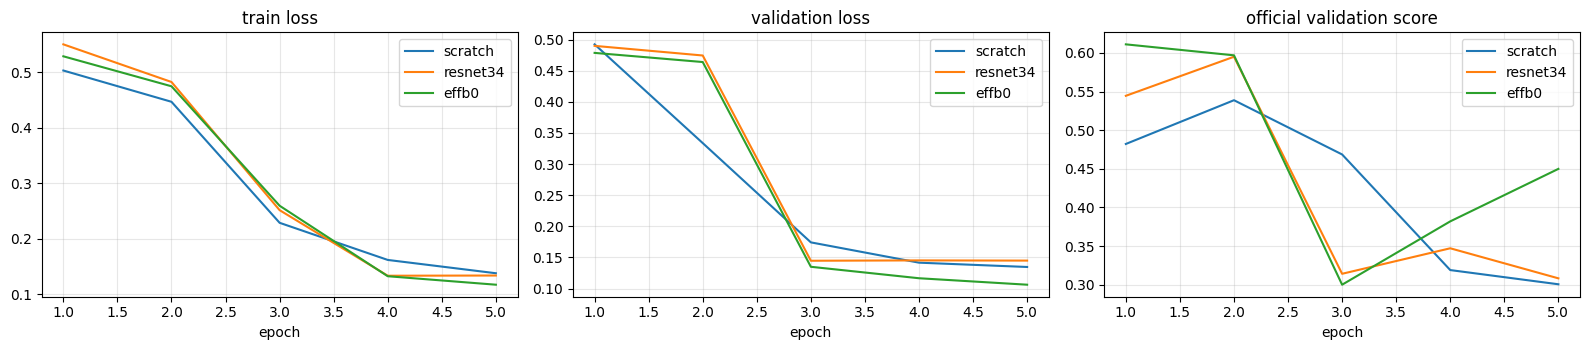

In [55]:
e = RESULTS["effb0"]["hist"].set_index("epoch")
p_r, p_e = RESULTS["resnet34"]["params"], RESULTS["effb0"]["params"]
ratio = round(p_r / p_e)
edge = "efficientnet-b0" if p_e < p_r else "resnet34"                      # smaller model / weight footprint -> edge deployment
competitive = "Yes" if e.val_score[E] >= r.val_score[E] - 0.01 else "No"
print(f"(1) parameters: ResNet-34 U-Net {p_r / 1e6:.2f} M | EfficientNet-B0 U-Net {p_e / 1e6:.2f} M -> ratio {p_r / p_e:.2f} -> {ratio}x ({100 * (1 - p_e / p_r):.0f} % fewer)")
print(f"(2) peak GPU VRAM while training (batch {BATCH}, AMP): ResNet-34 {RESULTS['resnet34']['vram_mb']:.0f} MB | EfficientNet-B0 {RESULTS['effb0']['vram_mb']:.0f} MB -> smaller model for edge deployment: {edge}")
if RESULTS['effb0']['vram_mb'] > RESULTS['resnet34']['vram_mb']:
    print("    note: EfficientNet-B0 has far fewer weights, but its depthwise/swish activations can need MORE training memory at large inputs; the answer follows model size / weight footprint, the usual edge-deployment criterion.")
print(f"(3) score at epoch {E}: ResNet-34 {r.val_score[E]:.4f} | EfficientNet-B0 {e.val_score[E]:.4f} -> competitive or better (within 0.01)? {competitive}")
conv = "Depthwise separable convolution (MBConv inverted-residual blocks: depthwise 3x3/5x5 + pointwise 1x1)"
print("(4)", conv)
ANS["Q9"] = f"{ratio}; {edge}; {competitive}; {conv}"
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for k, res in RESULTS.items():
    h = res["hist"]; ax[0].plot(h.epoch, h.train_loss, label=k); ax[1].plot(h.epoch, h.val_loss, label=k); ax[2].plot(h.epoch, h.val_score, label=k)
for a, t in zip(ax, ["train loss", "validation loss", "official validation score"]): a.set_title(t); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## ✅ ANSWER SHEET — copy each line into the matching Google-Form box
Q1–Q7 do not depend on training. Q8 and Q9 depend on your own runs (logged in W&B as `m3_scratch`, `m3_resnet34`, `m3_effb0`) — always paste the values printed by **your** final run.

In [56]:
lines = [f"{q}:  {ANS[q]}" for q in ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7", "Q8", "Q9"]]
sheet = "\n\n".join(lines)
print("=" * 100, "\nANSWER SHEET (exact answer formats)\n" + "=" * 100 + "\n\n" + sheet)
open(f"{OUT_DIR}/milestone3_answers.txt", "w").write(sheet); json.dump(ANS, open(f"{OUT_DIR}/milestone3_answers.json", "w"), indent=2)
try: wandb.init(project=WANDB_PROJECT, name="m3_answers", reinit=True, config={k: str(v) for k, v in ANS.items()}); wandb.finish()
except Exception as e: print("W&B answer log skipped:", repr(e)[:80])
print("\nsaved:", f"{OUT_DIR}/milestone3_answers.txt")

ANSWER SHEET (exact answer formats)

Q1:  8, 50; 1; 256

Q2:  efficientnet-b0, 18179204; 12.9

Q3:  sum, 3

Q4:  13, 25; ASPP runs parallel dilated convolutions with different rates, so small rates keep full-resolution detail for 1-3 px hairline cracks (defect_a) while large rates give wide context for big diffuse patches (defect_c) - a large receptive field and multi-scale context without pooling away resolution or adding parameters, unlike a pooling bottleneck.

Q5:  0.9851, 0.0524

Q6:  Yes; Softmax forces every pixel into exactly one class, so if annotations ever overlap the classes compete for the same pixel: one label is suppressed or the probabilities are split, causing missed or under-confident detections, whereas independent sigmoid channels can mark a pixel as several defects.

Q7:  On a clean image Dice loss is 0 for an empty prediction, but as soon as stray pixels appear it jumps to about 0.98 almost regardless of how few there are (a step-like penalty), while its gradient 


saved: /kaggle/working/milestone3_answers.txt
